In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
orders = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_orders_dataset.csv")

customers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_customers_dataset.csv")

order_items = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_items_dataset.csv")

products = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_products_dataset.csv")

sellers = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_sellers_dataset.csv")

payments = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_payments_dataset.csv")

reviews = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_order_reviews_dataset.csv")

geolocation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\olist_geolocation_dataset.csv")

category_translation = pd.read_csv(r"C:\Users\LATO\Documents\Sales Analysis\Data\product_category_name_translation.csv")

### Check Relation ship before eda

In [3]:
print("Orders customer_id:", orders["customer_id"].nunique())
print("Customers customer_id:", customers["customer_id"].nunique())

Orders customer_id: 99441
Customers customer_id: 99441


In [4]:
print("Orders:", orders["order_id"].nunique())
print("Order Items:", order_items["order_id"].nunique())

Orders: 99441
Order Items: 98666


In [5]:
print("Orders:", orders["order_id"].nunique())
print("Orders in reviews:", reviews["order_id"].nunique())

Orders: 99441
Orders in reviews: 98673


# Create order-level analysis table

In [6]:
order_analysis = orders.copy()

print("Rows:", len(order_analysis))
print("Columns:", order_analysis.shape[1])

Rows: 99441
Columns: 8


In [7]:
# Calculate total order value

order_revenue = (
    order_items
    .groupby("order_id")
    .agg(
        total_order_value=("price", "sum"),
        total_freight=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

In [8]:
order_revenue.head()

,order_id,total_order_value,total_freight,total_items
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1


In [9]:
order_analysis = order_analysis.merge(
    order_revenue,
    on="order_id",
    how="left"
)

In [10]:
order_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_order_value,total_freight,total_items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,29.99,8.72,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,118.70,22.76,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,159.90,19.22,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,45.00,27.20,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,19.90,8.72,1.0


# Create order-level analysis table

In [11]:
product_sales = (
    order_items
    .groupby("product_id")
    .agg(
        total_items_sold=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        total_freight=("freight_value", "sum"),
        average_price=("price", "mean")
    )
    .reset_index()
)

In [12]:
product_sales.head()

,product_id,total_items_sold,total_revenue,total_freight,average_price
0,00066f42aeeb9f3007548bb9d3f33c38,1,101.65,18.59,101.65
1,00088930e925c41fd95ebfe695fd2655,1,129.90,13.93,129.90
2,0009406fd7479715e4bef61dd91f2462,1,229.00,13.10,229.00
3,000b8f95fcb9e0096488278317764d19,2,117.80,39.20,58.90
4,000d9be29b5207b54e86aa1b1ac54872,1,199.00,19.27,199.00


In [13]:
product_analysis = products.merge(
    product_sales,
    on="product_id",
    how="left"
)

In [14]:
product_analysis.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,total_items_sold,total_revenue,total_freight,average_price
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,1,10.91,7.39,10.91
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,1,248.00,17.99,248.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,1,79.80,7.82,79.80
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,1,112.30,9.54,112.30
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,1,37.90,8.29,37.90


### Customer-Level Analysis Table

In [15]:
customer_sales = (
    order_analysis
    .groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("total_order_value", "sum"),
        average_order_value=("total_order_value", "mean")
    )
    .reset_index()
)

In [16]:
customer_analysis = customers.merge(
    customer_sales,
    on="customer_id",
    how="left"
)

In [17]:
customer_analysis.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_orders,total_spending,average_order_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,1,124.99,124.99
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,1,289.00,289.00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,1,139.94,139.94
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,1,149.94,149.94
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,1,230.00,230.00


In [18]:
print("Order Analysis:", order_analysis.shape)
print("Product Analysis:", product_analysis.shape)
print("Customer Analysis:", customer_analysis.shape)

Order Analysis: (99441, 11)
Product Analysis: (32951, 13)
Customer Analysis: (99441, 8)


## Business Overview
This section provides a high-level overview of the Olist
e-commerce business using key performance indicators (KPIs).

In [19]:
# 5.1 Business Overview KPIs

# Total orders
total_orders = orders["order_id"].nunique()

# Total unique customers
total_customers = customers["customer_unique_id"].nunique()

# Total products
total_products = products["product_id"].nunique()

# Total sellers
total_sellers = sellers["seller_id"].nunique()

# Total items sold
total_items_sold = order_items["order_item_id"].count()

# Total product revenue (excluding freight)
total_revenue = order_items["price"].sum()

# Total freight charges
total_freight = order_items["freight_value"].sum()

# Average order value, based on product prices
average_order_value = (
    order_analysis["total_order_value"].sum()
    / order_analysis["total_order_value"].count()
)

# Average review score
average_review_score = reviews["review_score"].mean()

In [20]:
# 5.2 Display Business KPIs

business_overview = pd.DataFrame({
    "KPI": [
        "Total Orders",
        "Total Unique Customers",
        "Total Products",
        "Total Sellers",
        "Total Items Sold",
        "Total Product Revenue",
        "Total Freight Charges",
        "Average Order Value",
        "Average Review Score"
    ],
    "Value": [
        total_orders,
        total_customers,
        total_products,
        total_sellers,
        total_items_sold,
        total_revenue,
        total_freight,
        average_order_value,
        average_review_score
    ]
})

business_overview

,KPI,Value
0,Total Orders,9.944100e+04
1,Total Unique Customers,9.609600e+04
2,Total Products,3.295100e+04
3,Total Sellers,3.095000e+03
4,Total Items Sold,1.126500e+05
5,Total Product Revenue,1.359164e+07
6,Total Freight Charges,2.251910e+06
7,Average Order Value,1.377541e+02
8,Average Review Score,4.086421e+00


In [21]:
business_overview.style.format({
    "Value": lambda x: f"{x:,.2f}"
})

,KPI,Value
0,Total Orders,"99,441.00"
1,Total Unique Customers,"96,096.00"
2,Total Products,"32,951.00"
3,Total Sellers,"3,095.00"
4,Total Items Sold,"112,650.00"
5,Total Product Revenue,"13,591,643.70"
6,Total Freight Charges,"2,251,909.54"
7,Average Order Value,137.75
8,Average Review Score,4.09


In [22]:
print("Orders:", total_orders)
print("Customers:", total_customers)
print("Products:", total_products)
print("Sellers:", total_sellers)
print("Items Sold:", total_items_sold)
print("Total Product Revenue:", round(total_revenue, 2))
print("Average Order Value:", round(average_order_value, 2))
print("Average Review Score:", round(average_review_score, 2))

Orders: 99441
Customers: 96096
Products: 32951
Sellers: 3095
Items Sold: 112650
Total Product Revenue: 13591643.7
Average Order Value: 137.75
Average Review Score: 4.09


## Sales Analysis
## Monthly Revenue Analysis

In [23]:
# Check purchase date data type
orders["order_purchase_timestamp"].dtype

dtype('O')

In [24]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [25]:
# Get the purchase date for each order
order_dates = orders[
    ["order_id", "order_purchase_timestamp"]
].copy()

# Calculate revenue for each order
order_revenue = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(total_revenue=("price", "sum"))
)

# Attach purchase dates to order revenue
sales_data = order_revenue.merge(
    order_dates,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Create a monthly period
sales_data["purchase_month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate revenue by month
monthly_revenue = (
    sales_data
    .groupby("purchase_month", as_index=False)
    .agg(monthly_revenue=("total_revenue", "sum"))
)

monthly_revenue.head()

,purchase_month,monthly_revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02


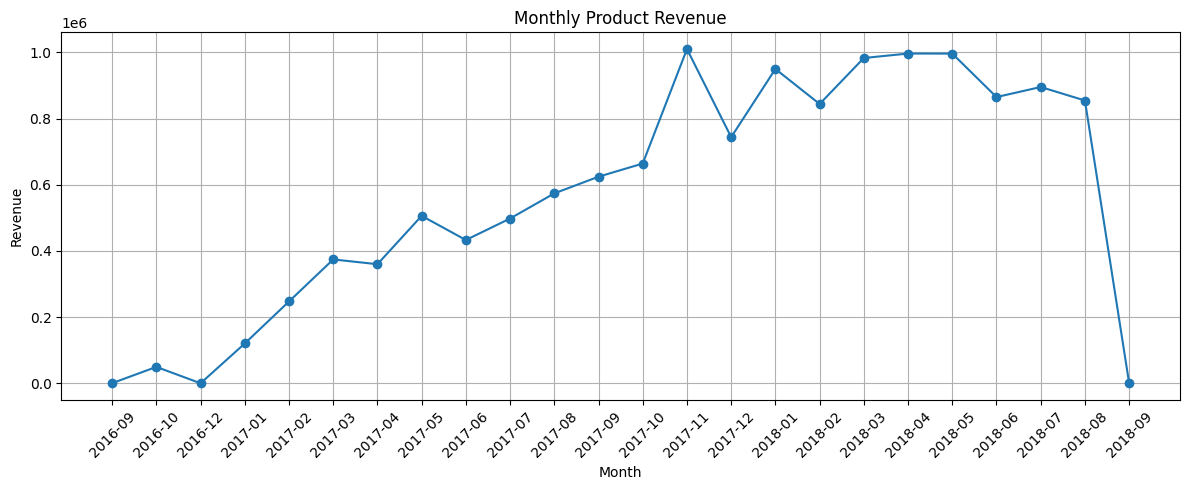

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["purchase_month"].astype(str),
    monthly_revenue["monthly_revenue"],
    marker="o"
)

plt.title("Monthly Product Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
highest_month = monthly_revenue.loc[
    monthly_revenue["monthly_revenue"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["monthly_revenue"].idxmin()
]

print("Highest revenue month:")
print(highest_month)

print("\nLowest revenue month:")
print(lowest_month)

Highest revenue month:
purchase_month        2017-11
monthly_revenue    1010271.37
Name: 13, dtype: object

Lowest revenue month:
purchase_month     2016-12
monthly_revenue       10.9
Name: 2, dtype: object


## Monthly Orders

In [28]:
# 6.2 Monthly Orders Analysis

# Ensure purchase timestamp is datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

# Create a copy for analysis
orders_data = orders[
    ["order_id", "order_purchase_timestamp"]
].copy()

# Extract the month
orders_data["purchase_month"] = (
    orders_data["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly order counts
monthly_orders = (
    orders_data
    .groupby("purchase_month")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
)

# Display results
monthly_orders.head()

,purchase_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780


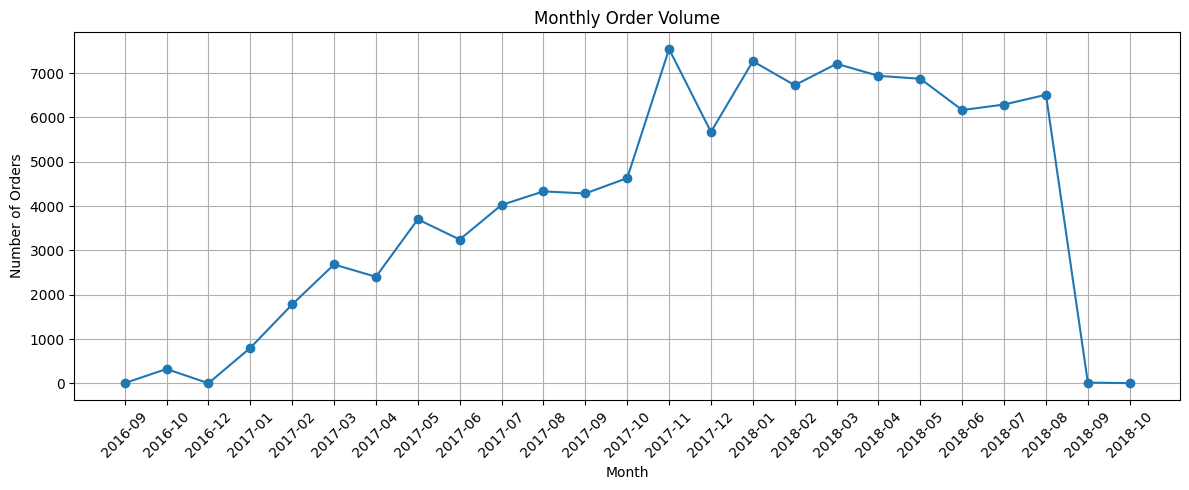

In [29]:
# Plot monthly orders

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders["purchase_month"].astype(str),
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
# Highest-order month
highest_orders_month = monthly_orders.loc[
    monthly_orders["total_orders"].idxmax()
]

# Lowest-order month
lowest_orders_month = monthly_orders.loc[
    monthly_orders["total_orders"].idxmin()
]

print("Highest-order month:")
print(highest_orders_month)

print("\nLowest-order month:")
print(lowest_orders_month)

Highest-order month:
purchase_month    2017-11
total_orders         7544
Name: 13, dtype: object

Lowest-order month:
purchase_month    2016-12
total_orders            1
Name: 2, dtype: object


In [31]:
# Calculate percentage change from the previous month
monthly_orders["order_growth_pct"] = (
    monthly_orders["total_orders"].pct_change() * 100
)

monthly_orders.head(10)

,purchase_month,total_orders,order_growth_pct
0,2016-09,4,NaN
1,2016-10,324,8000.000000
2,2016-12,1,-99.691358
3,2017-01,800,79900.000000
4,2017-02,1780,122.500000
5,2017-03,2682,50.674157
6,2017-04,2404,-10.365399
7,2017-05,3700,53.910150
8,2017-06,3245,-12.297297
9,2017-07,4026,24.067797


## Average Order Value (AOV)

In [32]:
# 6.3 Average Order Value (AOV) Analysis

# Create monthly AOV
monthly_aov = (
    sales_data
    .groupby("purchase_month", as_index=False)
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_orders=("order_id", "nunique")
    )
)

# Calculate AOV
monthly_aov["average_order_value"] = (
    monthly_aov["total_revenue"] / monthly_aov["total_orders"]
)

# Display results
monthly_aov.head(10)

,purchase_month,total_revenue,total_orders,average_order_value
0,2016-09,267.36,3,89.120000
1,2016-10,49507.66,308,160.739156
2,2016-12,10.90,1,10.900000
3,2017-01,120312.87,789,152.487795
4,2017-02,247303.02,1733,142.702262
5,2017-03,374344.30,2641,141.743393
6,2017-04,359927.23,2391,150.534182
7,2017-05,506071.14,3660,138.270803
8,2017-06,433038.60,3217,134.609450
9,2017-07,498031.48,3969,125.480343


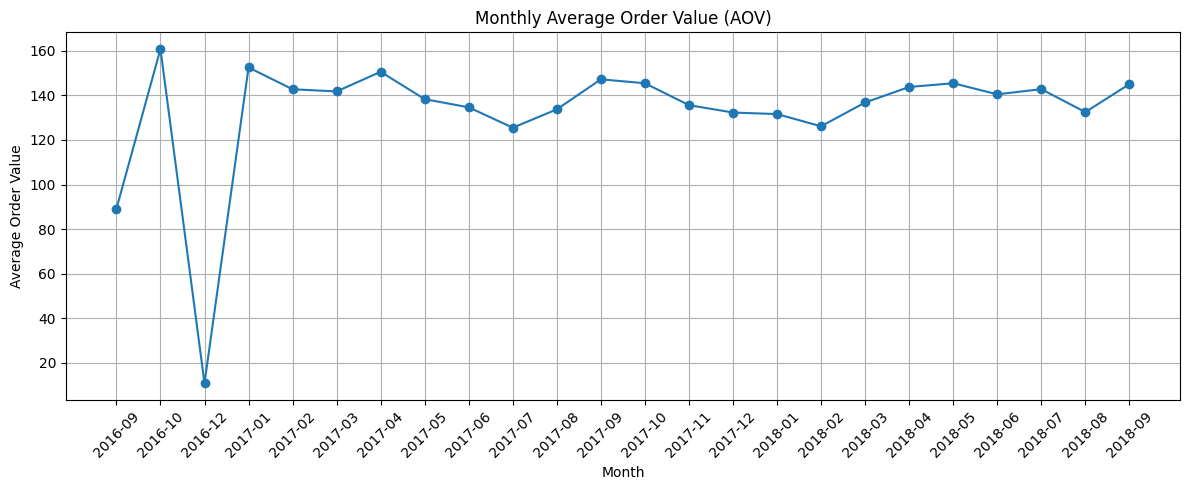

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_aov["purchase_month"].astype(str),
    monthly_aov["average_order_value"],
    marker="o"
)

plt.title("Monthly Average Order Value (AOV)")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
highest_aov_month = monthly_aov.loc[
    monthly_aov["average_order_value"].idxmax()
]

lowest_aov_month = monthly_aov.loc[
    monthly_aov["average_order_value"].idxmin()
]

print("Highest AOV month:")
print(highest_aov_month)

print("\nLowest AOV month:")
print(lowest_aov_month)

Highest AOV month:
purchase_month            2016-10
total_revenue            49507.66
total_orders                  308
average_order_value    160.739156
Name: 1, dtype: object

Lowest AOV month:
purchase_month         2016-12
total_revenue             10.9
total_orders                 1
average_order_value       10.9
Name: 2, dtype: object


In [35]:
overall_aov = (
    sales_data["total_revenue"].sum()
    / sales_data["order_id"].nunique()
)

print(f"Overall AOV: R$ {overall_aov:,.2f}")

Overall AOV: R$ 137.75


## Order Status Analysis

In [36]:
status_counts = orders["order_status"].value_counts()

print(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [37]:
status_analysis = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_analysis.columns = ["order_status", "total_orders"]

status_analysis["percentage"] = (
    status_analysis["total_orders"] / len(orders) * 100
)

status_analysis

,order_status,total_orders,percentage
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


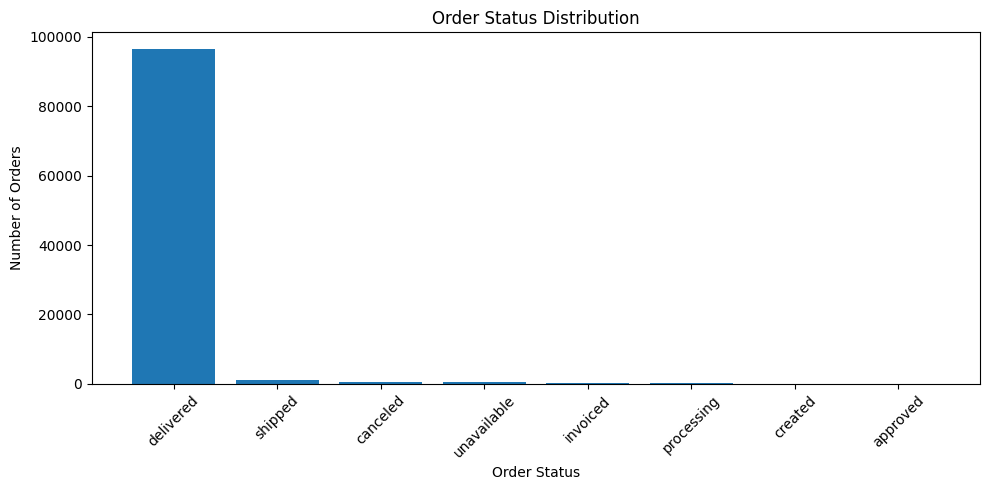

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    status_analysis["order_status"],
    status_analysis["total_orders"]
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Product Analysis

In [39]:
print(product_analysis.shape)
product_analysis.head()

(32951, 13)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,total_items_sold,total_revenue,total_freight,average_price
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,1,10.91,7.39,10.91
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,1,248.00,17.99,248.00
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,1,79.80,7.82,79.80
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,1,112.30,9.54,112.30
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,1,37.90,8.29,37.90


## Top Products

In [40]:
top_products = (
    product_analysis
    .sort_values("total_items_sold", ascending=False)
    .head(10)
)

top_products[
    ["product_id", "total_items_sold", "total_revenue", "average_price"]
]

,product_id,total_items_sold,total_revenue,average_price
13430,aca2eb7d00ea1a7b8ebd4e68314663af,527,37608.90,71.364137
9661,99a4788cb24856965c36a24e339b6058,488,43025.56,88.167131
14051,422879e10f46682990de24d770e7f83d,484,26577.22,54.911612
30293,389d119b48cf3043d311335e499d9c6b,392,21440.59,54.695383
4598,368c6c730842d78016ad823897a372db,388,21056.80,54.270103
32098,53759a2ecddad2bb87a079a1f1519f73,373,20387.20,54.657373
8290,d1c427060a0f73f6b889a5c7c61f2ac4,343,47214.51,137.651633
793,53b36df67ebb7c41585e8d54d6772e08,323,37683.42,116.666935
1749,154e7e31ebfa092203795c972e5804a6,281,6325.19,22.509573
29129,3dd2a17168ec895c781a9191c1e95ad7,274,41082.60,149.936496


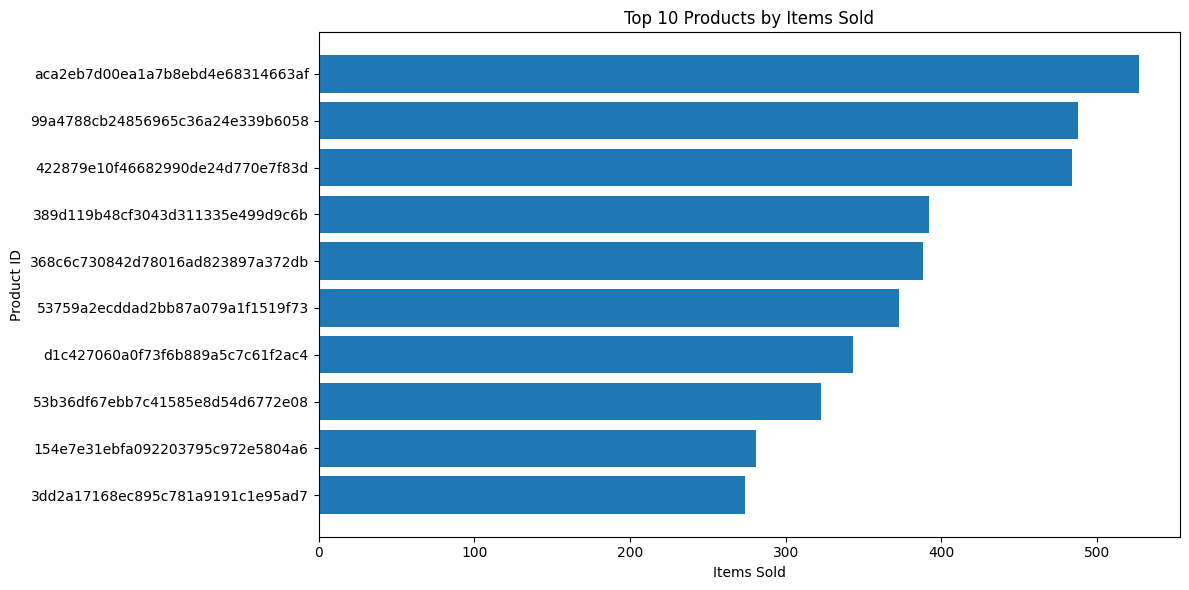

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_products["product_id"].astype(str),
    top_products["total_items_sold"]
)

plt.title("Top 10 Products by Items Sold")
plt.xlabel("Items Sold")
plt.ylabel("Product ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Top Categories

In [42]:
top_categories = (
    product_analysis
    .groupby("product_category_name", dropna=False)
    .agg(
        total_items_sold=("total_items_sold", "sum"),
        total_revenue=("total_revenue", "sum")
    )
    .sort_values("total_items_sold", ascending=False)
    .head(10)
    .reset_index()
)

top_categories

,product_category_name,total_items_sold,total_revenue
0,cama_mesa_banho,11115,1036988.68
1,beleza_saude,9670,1258681.34
2,esporte_lazer,8641,988048.97
3,moveis_decoracao,8334,729762.49
4,informatica_acessorios,7827,911954.32
5,utilidades_domesticas,6964,632248.66
6,relogios_presentes,5991,1205005.68
7,telefonia,4545,323667.53
8,ferramentas_jardim,4347,485256.46
9,automotivo,4235,592720.11


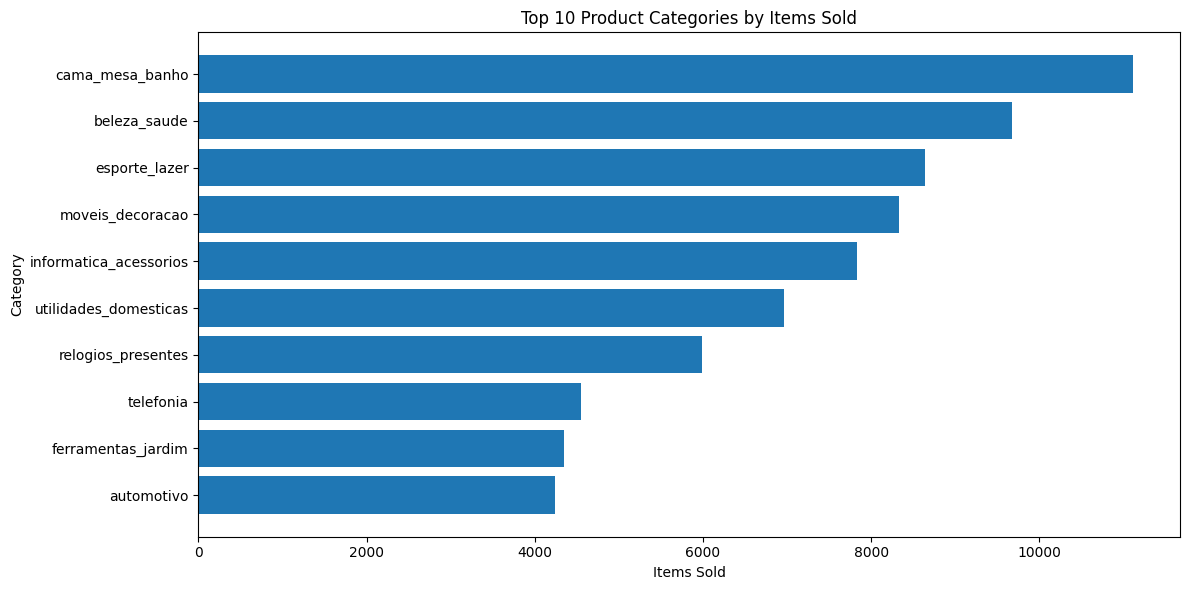

In [43]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_categories["product_category_name"].fillna("Unknown"),
    top_categories["total_items_sold"]
)

plt.title("Top 10 Product Categories by Items Sold")
plt.xlabel("Items Sold")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Revenue by Category

In [44]:
revenue_by_category = (
    product_analysis
    .groupby("product_category_name", dropna=False)
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_items_sold=("total_items_sold", "sum")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

revenue_by_category.head(10)

,product_category_name,total_revenue,total_items_sold
0,beleza_saude,1258681.34,9670
1,relogios_presentes,1205005.68,5991
2,cama_mesa_banho,1036988.68,11115
3,esporte_lazer,988048.97,8641
4,informatica_acessorios,911954.32,7827
5,moveis_decoracao,729762.49,8334
6,cool_stuff,635290.85,3796
7,utilidades_domesticas,632248.66,6964
8,automotivo,592720.11,4235
9,ferramentas_jardim,485256.46,4347


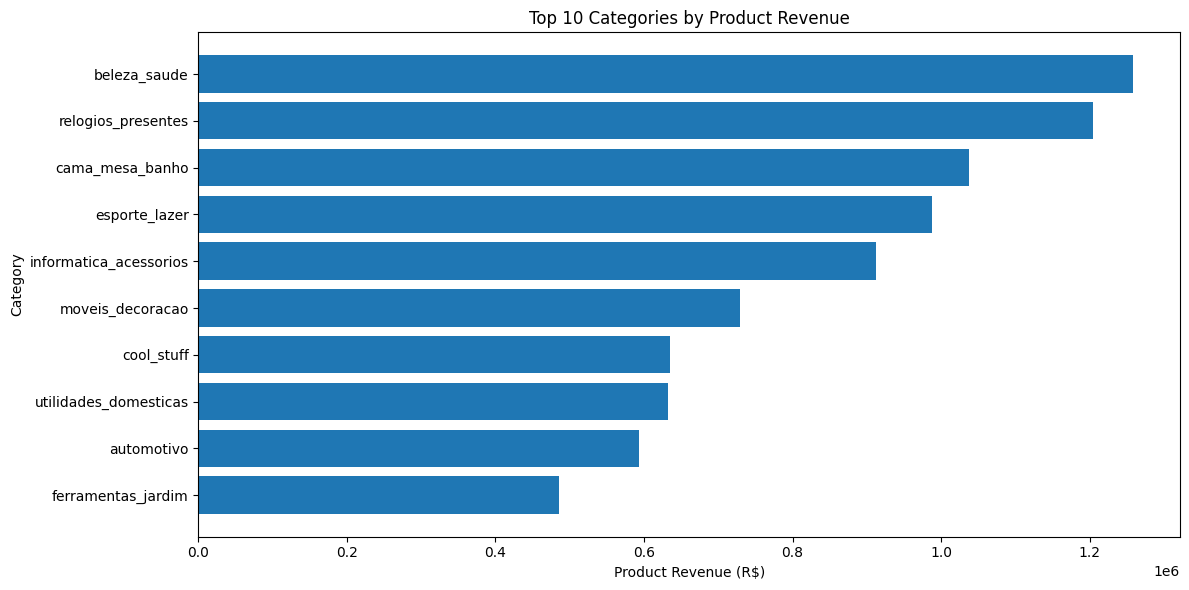

In [45]:
top_revenue_categories = revenue_by_category.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_revenue_categories["product_category_name"].fillna("Unknown"),
    top_revenue_categories["total_revenue"]
)

plt.title("Top 10 Categories by Product Revenue")
plt.xlabel("Product Revenue (R$)")
plt.ylabel("Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [46]:
total_category_revenue = revenue_by_category["total_revenue"].sum()

revenue_by_category["revenue_percentage"] = (
    revenue_by_category["total_revenue"]
    / total_category_revenue * 100
)

revenue_by_category.head(10)

,product_category_name,total_revenue,total_items_sold,revenue_percentage
0,beleza_saude,1258681.34,9670,9.260700
1,relogios_presentes,1205005.68,5991,8.865783
2,cama_mesa_banho,1036988.68,11115,7.629605
3,esporte_lazer,988048.97,8641,7.269533
4,informatica_acessorios,911954.32,7827,6.709669
5,moveis_decoracao,729762.49,8334,5.369200
6,cool_stuff,635290.85,3796,4.674128
7,utilidades_domesticas,632248.66,6964,4.651745
8,automotivo,592720.11,4235,4.360916
9,ferramentas_jardim,485256.46,4347,3.570256


## Price Analysis

In [47]:
price_summary = order_items["price"].describe()

print(price_summary)

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64


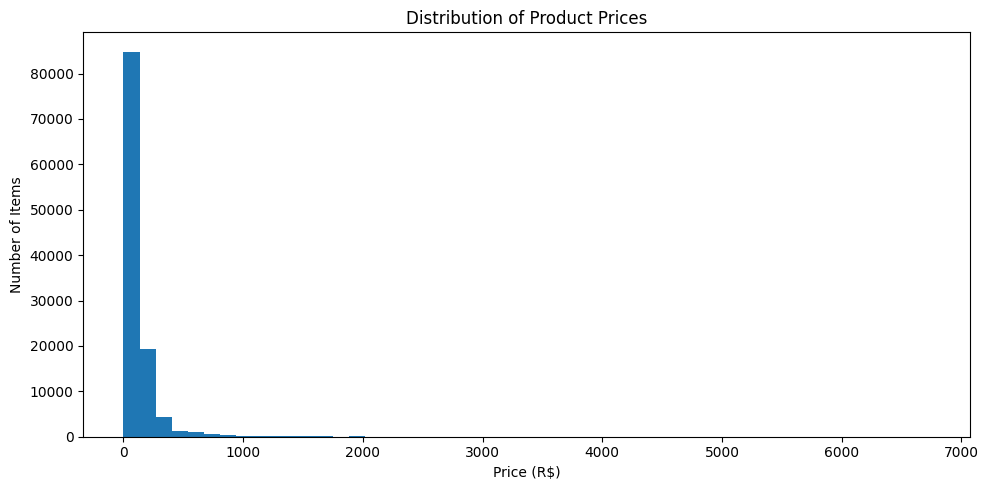

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(order_items["price"].dropna(), bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price (R$)")
plt.ylabel("Number of Items")
plt.tight_layout()
plt.show()

In [49]:
Q1 = order_items["price"].quantile(0.25)
Q3 = order_items["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = order_items[
    (order_items["price"] < lower_bound) |
    (order_items["price"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Price Outliers:", len(price_outliers))

Lower Bound: -102.6
Upper Bound: 277.4
Number of Price Outliers: 8427


## Customer Analysis

In [50]:
print(customer_analysis.shape)
customer_analysis.head()

(99441, 8)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_orders,total_spending,average_order_value
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,1,124.99,124.99
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,1,289.00,289.00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,1,139.94,139.94
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,1,149.94,149.94
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,1,230.00,230.00


## Customer Orders

In [51]:
customer_orders = (
    orders[["order_id", "customer_id"]]
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_state",
                "customer_city"
            ]
        ],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

print("Shape:", customer_orders.shape)
customer_orders.head()

Shape: (99441, 5)


,order_id,customer_id,customer_unique_id,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre


In [52]:
order_values = (
    order_items.groupby("order_id")
    .agg(
        order_spending=("price", "sum"),
        items_purchased=("order_item_id", "count")
    )
    .reset_index()
)

customer_orders = customer_orders.merge(
    order_values,
    on="order_id",
    how="left",
    validate="one_to_one"
)

customer_orders.head()

,order_id,customer_id,customer_unique_id,customer_state,customer_city,order_spending,items_purchased
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo,29.99,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,BA,barreiras,118.70,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis,159.90,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante,45.00,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre,19.90,1.0


In [53]:
customer_order_counts = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

customer_order_counts.head()

,customer_unique_id,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [54]:
customer_order_counts = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

customer_order_counts.head()

,customer_unique_id,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


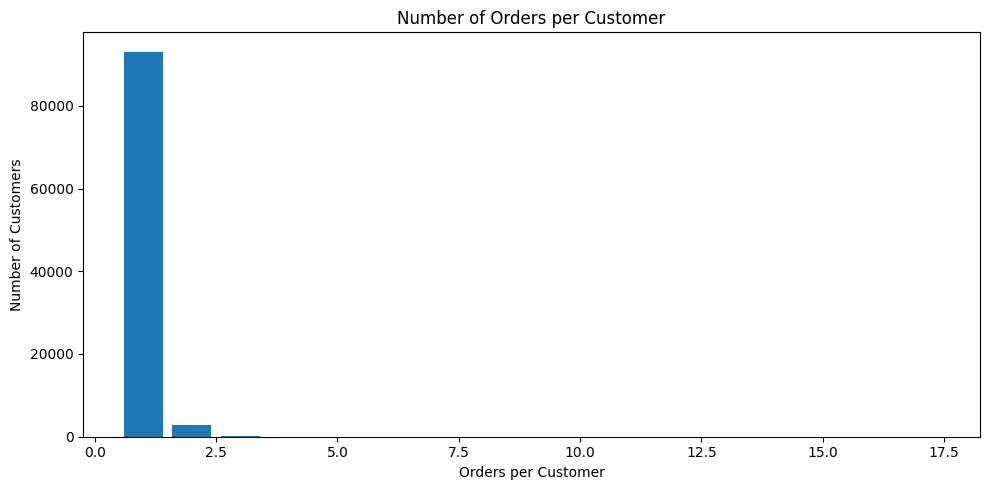

In [55]:
order_frequency = customer_order_counts["total_orders"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(order_frequency.index, order_frequency.values)

plt.title("Number of Orders per Customer")
plt.xlabel("Orders per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Customer Spending

In [56]:
customer_spending = (
    customer_orders
    .dropna(subset=["order_spending"])
    .groupby("customer_unique_id")
    .agg(
        total_spending=("order_spending", "sum"),
        average_order_value=("order_spending", "mean"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

customer_spending.head()

,customer_unique_id,total_spending,average_order_value,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90,129.90,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90,18.90,1
2,0000f46a3911fa3c0805444483337064,69.00,69.00,1
3,0000f6ccb0745a6a4b88665a16c9f078,25.99,25.99,1
4,0004aac84e0df4da2b147fca70cf8255,180.00,180.00,1


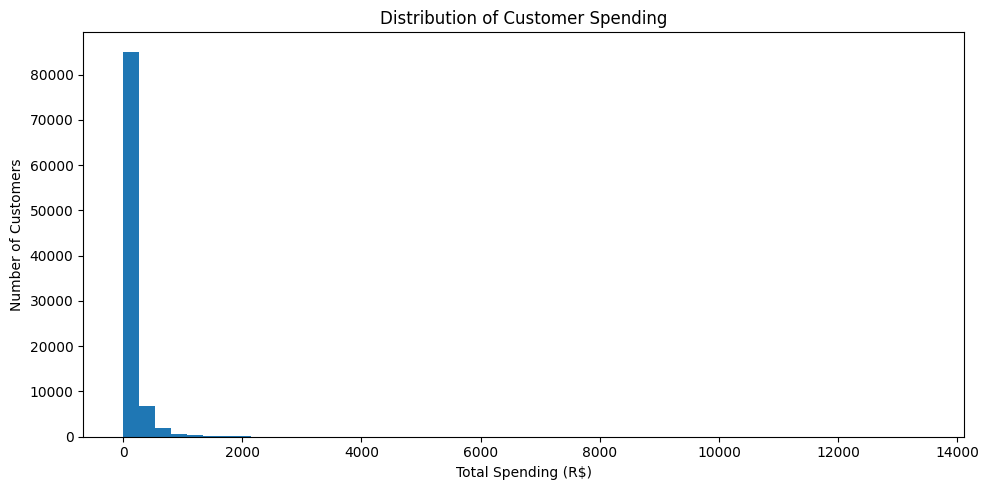

In [57]:
plt.figure(figsize=(10, 5))

plt.hist(customer_spending["total_spending"], bins=50)

plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending (R$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Repeat Customers

In [58]:
total_customers = len(customer_order_counts)

repeat_customers = (
    customer_order_counts["total_orders"] > 1
).sum()

one_time_customers = (
    customer_order_counts["total_orders"] == 1
).sum()

repeat_customer_pct = repeat_customers / total_customers * 100

print("Total Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print(f"Repeat Customer Percentage: {repeat_customer_pct:.2f}%")

Total Customers: 96096
One-Time Customers: 93099
Repeat Customers: 2997
Repeat Customer Percentage: 3.12%


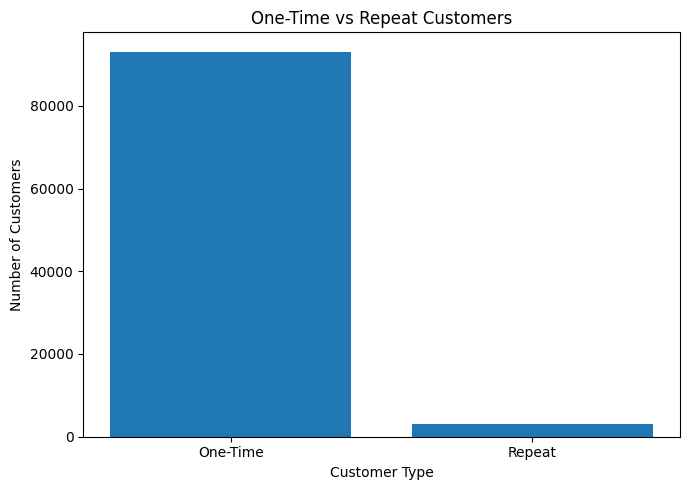

In [59]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["One-Time", "Repeat"],
    [one_time_customers, repeat_customers]
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Customer Geography

In [60]:
customer_geography = (
    customers
    .drop_duplicates("customer_unique_id")
    .groupby("customer_state")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .sort_values("total_customers", ascending=False)
    .reset_index()
)

customer_geography.head(10)

,customer_state,total_customers
0,SP,40295
1,RJ,12377
2,MG,11255
3,RS,5277
4,PR,4882
5,SC,3529
6,BA,3276
7,DF,2073
8,ES,1963
9,GO,1951


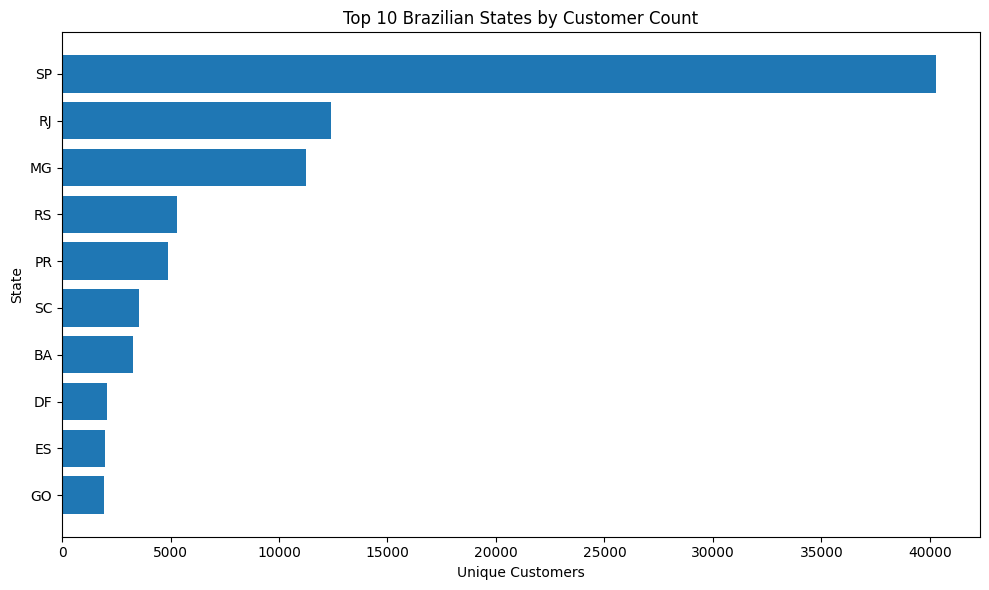

In [61]:
top_states = customer_geography.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["customer_state"],
    top_states["total_customers"]
)

plt.title("Top 10 Brazilian States by Customer Count")
plt.xlabel("Unique Customers")
plt.ylabel("State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [62]:
total_geographic_customers = customer_geography["total_customers"].sum()

customer_geography["customer_percentage"] = (
    customer_geography["total_customers"]
    / total_geographic_customers * 100
)

customer_geography.head(10)

,customer_state,total_customers,customer_percentage
0,SP,40295,41.932026
1,RJ,12377,12.879829
2,MG,11255,11.712246
3,RS,5277,5.491384
4,PR,4882,5.080336
5,SC,3529,3.672369
6,BA,3276,3.409091
7,DF,2073,2.157218
8,ES,1963,2.042749
9,GO,1951,2.030261


## Seller Analysis

In [63]:
seller_sales = (
    order_items.groupby("seller_id")
    .agg(
        total_items_sold=("order_item_id", "count"),
        total_revenue=("price", "sum"),
        average_item_price=("price", "mean"),
        total_freight=("freight_value", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

seller_analysis = sellers.merge(
    seller_sales,
    on="seller_id",
    how="left",
    validate="one_to_one"
)

seller_analysis.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state,total_items_sold,total_revenue,average_item_price,total_freight,total_orders
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,3,218.70,72.900000,27.90,3
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,41,11703.07,285.440732,1438.73,40
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,1,158.00,158.000000,16.21,1
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,1,79.99,79.990000,15.66,1
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,1,167.99,167.990000,31.93,1


## Top Sellers

In [64]:
top_sellers = (
    seller_analysis
    .sort_values("total_items_sold", ascending=False)
    .head(10)
)

top_sellers[
    ["seller_id", "total_items_sold", "total_revenue", "total_orders"]
]

,seller_id,total_items_sold,total_revenue,total_orders
797,6560211a19b47992c3666cc44a7e94c0,2033,123304.83,1854
2463,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,1806
474,1f50f920176fa81dab994f9023523100,1931,106939.21,1404
1413,cc419e0650a3c5ba77189a1882b7556a,1775,104288.42,1706
1873,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,1314
390,955fee9216a65b617aa5c0531780ce60,1499,135171.70,1287
2720,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,915
1182,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,982
987,ea8482cd71df3c1969d7b9473ff13abc,1203,37177.52,1146
2207,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,1160


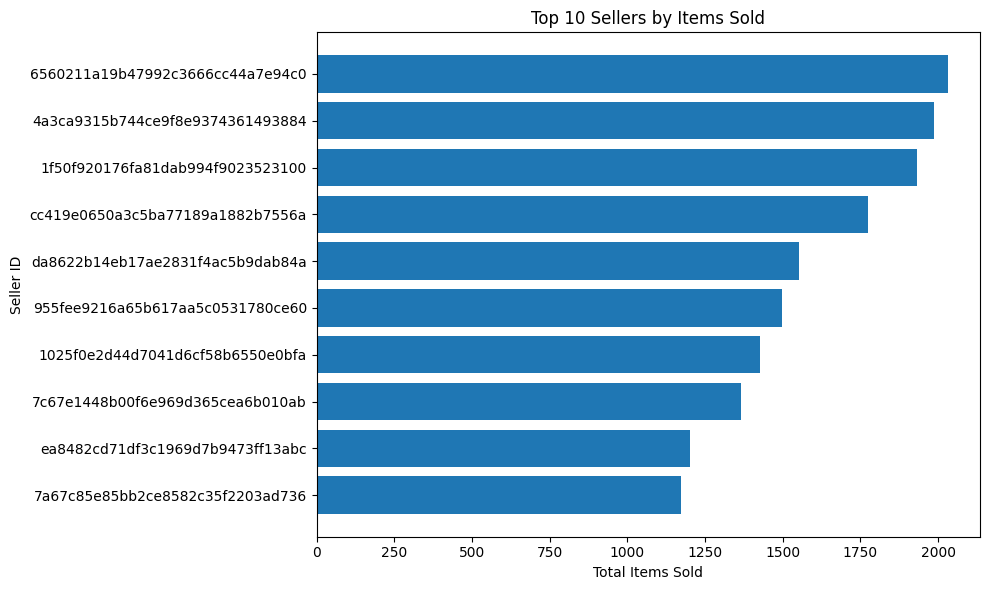

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_sellers["seller_id"].astype(str),
    top_sellers["total_items_sold"]
)

plt.title("Top 10 Sellers by Items Sold")
plt.xlabel("Total Items Sold")
plt.ylabel("Seller ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Seller Revenue

In [66]:
top_revenue_sellers = (
    seller_analysis
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

top_revenue_sellers[
    ["seller_id", "total_revenue", "total_items_sold", "total_orders"]
]

,seller_id,total_revenue,total_items_sold,total_orders
2617,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1156,1132
901,53243585a1d6dc2643021fd1853d8905,222776.05,410,358
2463,4a3ca9315b744ce9f8e9374361493884,200472.92,1987,1806
557,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,586,585
1182,7c67e1448b00f6e969d365cea6b010ab,187923.89,1364,982
68,7e93a43ef30c4f03f38b393420bc753a,176431.87,340,336
1873,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1551,1314
2207,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1171,1160
2720,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1428,915
390,955fee9216a65b617aa5c0531780ce60,135171.70,1499,1287


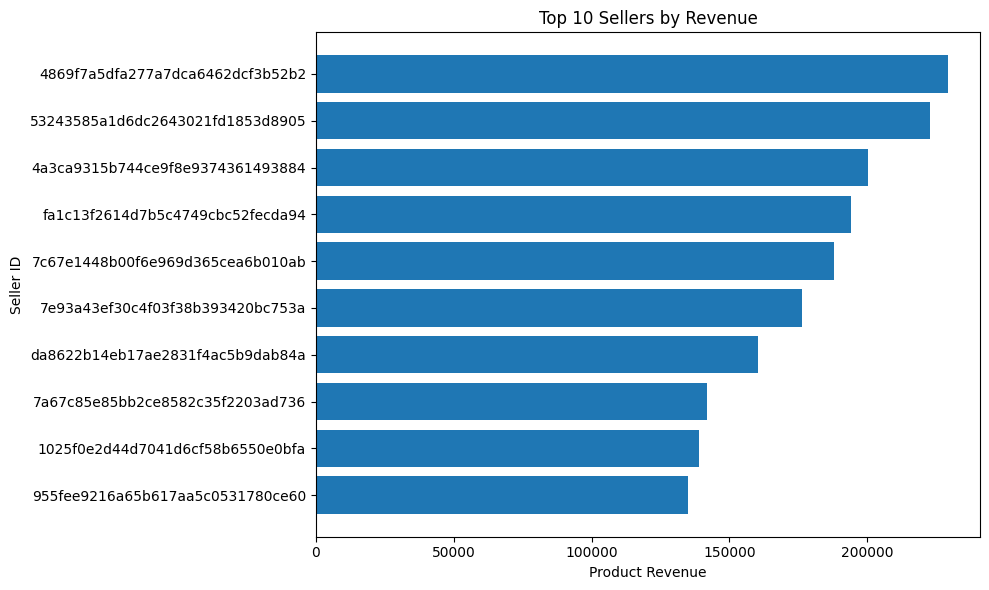

In [67]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_revenue_sellers["seller_id"].astype(str),
    top_revenue_sellers["total_revenue"]
)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Product Revenue")
plt.ylabel("Seller ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Seller Performance

In [68]:
seller_performance = seller_analysis[
    [
        "seller_id",
        "total_items_sold",
        "total_orders",
        "total_revenue",
        "average_item_price"
    ]
].copy()

seller_performance = seller_performance.sort_values(
    "total_orders",
    ascending=False
)

seller_performance.head(10)

,seller_id,total_items_sold,total_orders,total_revenue,average_item_price
797,6560211a19b47992c3666cc44a7e94c0,2033,1854,123304.83,60.651663
2463,4a3ca9315b744ce9f8e9374361493884,1987,1806,200472.92,100.892260
1413,cc419e0650a3c5ba77189a1882b7556a,1775,1706,104288.42,58.754039
474,1f50f920176fa81dab994f9023523100,1931,1404,106939.21,55.380223
1873,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,160236.57,103.311779
390,955fee9216a65b617aa5c0531780ce60,1499,1287,135171.70,90.174583
2207,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,141745.53,121.046567
987,ea8482cd71df3c1969d7b9473ff13abc,1203,1146,37177.52,30.904007
2617,4869f7a5dfa277a7dca6462dcf3b52b2,1156,1132,229472.63,198.505735
2345,3d871de0142ce09b7081e2b9d1733cb1,1147,1080,94914.20,82.749956


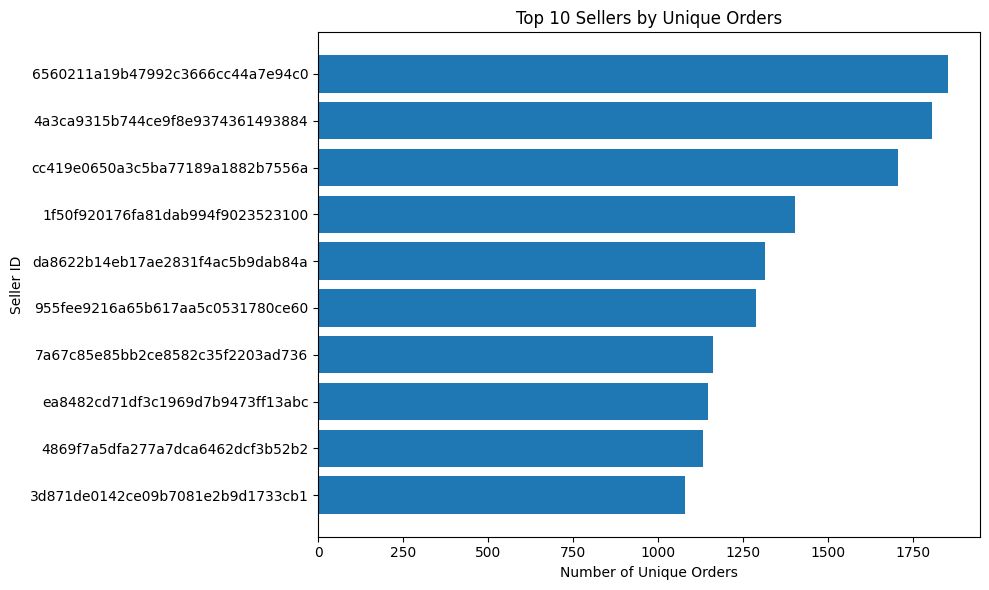

In [69]:
top_order_sellers = seller_performance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_order_sellers["seller_id"].astype(str),
    top_order_sellers["total_orders"]
)

plt.title("Top 10 Sellers by Unique Orders")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Seller ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [70]:
seller_performance["revenue_per_order"] = (
    seller_performance["total_revenue"]
    / seller_performance["total_orders"]
)

seller_performance[
    [
        "seller_id",
        "total_orders",
        "total_revenue",
        "revenue_per_order"
    ]
].sort_values(
    "revenue_per_order",
    ascending=False
).head(10)

,seller_id,total_orders,total_revenue,revenue_per_order
2916,80ceebb4ee9b31afb6c6a916a574a1e2,1,6729.00,6729.000000
520,ee27a8f15b1dded4d213a468ba4eb391,1,6499.00,6499.000000
1879,b37c4c02bda3161a7546a4e6d222d5b2,4,24075.00,6018.750000
639,585175ec331ea177fa47199e39a6170a,1,3549.00,3549.000000
1210,abe021b01ba992245271b9aa422032df,2,6720.00,3360.000000
2912,a00824eb9093d40e589b940ec45c4eb0,3,9399.97,3133.323333
1470,e2a1ac9bf33e5549a2a4f834e70df2f8,5,14999.45,2999.890000
855,e908c0f3646e8b60375734a350d95d71,1,2951.00,2951.000000
2213,d63c73efd41eb002280e7ec831424edb,2,5598.00,2799.000000
15,1444c08e64d55fb3c25f0f09c07ffcf2,1,2749.00,2749.000000


### Payment Analysis

In [71]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### Payment Methods

In [72]:
payment_methods = (
    payments.groupby("payment_type")
    .agg(
        total_payment_records=("order_id", "count"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
    .sort_values("total_payment_records", ascending=False)
)

payment_methods

,payment_type,total_payment_records,total_payment_value
1,credit_card,76795,12542084.19
0,boleto,19784,2869361.27
4,voucher,5775,379436.87
2,debit_card,1529,217989.79
3,not_defined,3,0.00


In [73]:
payment_methods["percentage"] = (
    payment_methods["total_payment_records"]
    / payment_methods["total_payment_records"].sum()
    * 100
)

payment_methods

,payment_type,total_payment_records,total_payment_value,percentage
1,credit_card,76795,12542084.19,73.922376
0,boleto,19784,2869361.27,19.043952
4,voucher,5775,379436.87,5.558978
2,debit_card,1529,217989.79,1.471806
3,not_defined,3,0.00,0.002888


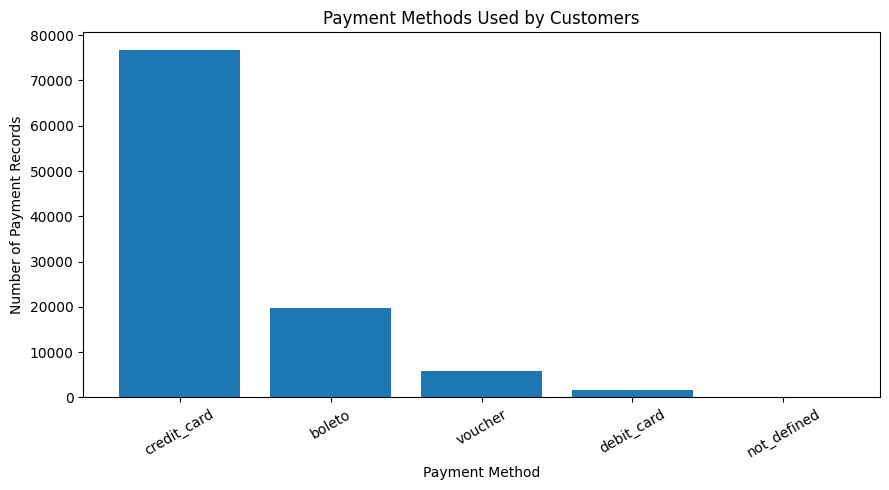

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    payment_methods["payment_type"],
    payment_methods["total_payment_records"]
)

plt.title("Payment Methods Used by Customers")
plt.xlabel("Payment Method")
plt.ylabel("Number of Payment Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Payment Value

In [75]:
payment_value_analysis = (
    payments.groupby("payment_type")
    .agg(
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean"),
        median_payment_value=("payment_value", "median"),
        payment_records=("payment_value", "count")
    )
    .reset_index()
    .sort_values("total_payment_value", ascending=False)
)

payment_value_analysis

,payment_type,total_payment_value,average_payment_value,median_payment_value,payment_records
1,credit_card,12542084.19,163.319021,106.87,76795
0,boleto,2869361.27,145.034435,93.89,19784
4,voucher,379436.87,65.703354,39.28,5775
2,debit_card,217989.79,142.570170,89.30,1529
3,not_defined,0.00,0.000000,0.00,3


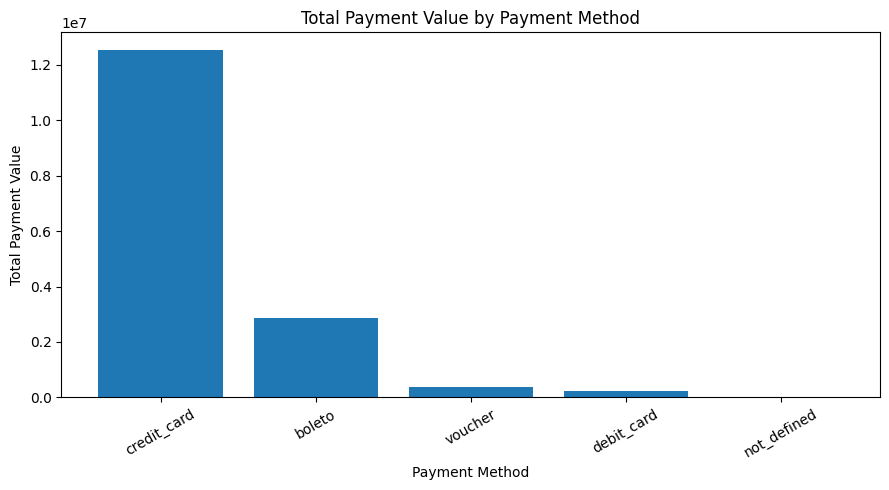

In [76]:
plt.figure(figsize=(9, 5))

plt.bar(
    payment_value_analysis["payment_type"],
    payment_value_analysis["total_payment_value"]
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [77]:
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

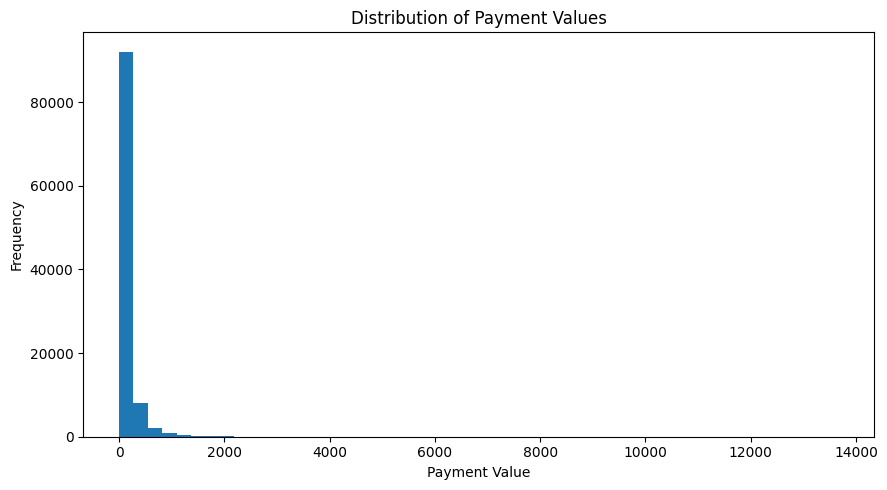

In [78]:
plt.figure(figsize=(9, 5))

plt.hist(payments["payment_value"].dropna(), bins=50)

plt.title("Distribution of Payment Values")
plt.xlabel("Payment Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Installments

In [79]:
installment_counts = (
    payments["payment_installments"]
    .value_counts()
    .sort_index()
    .reset_index()
)

installment_counts.columns = [
    "installments",
    "payment_records"
]

installment_counts.head(20)

,installments,payment_records
0,0,2
1,1,52546
2,2,12413
3,3,10461
4,4,7098
5,5,5239
6,6,3920
7,7,1626
8,8,4268
9,9,644


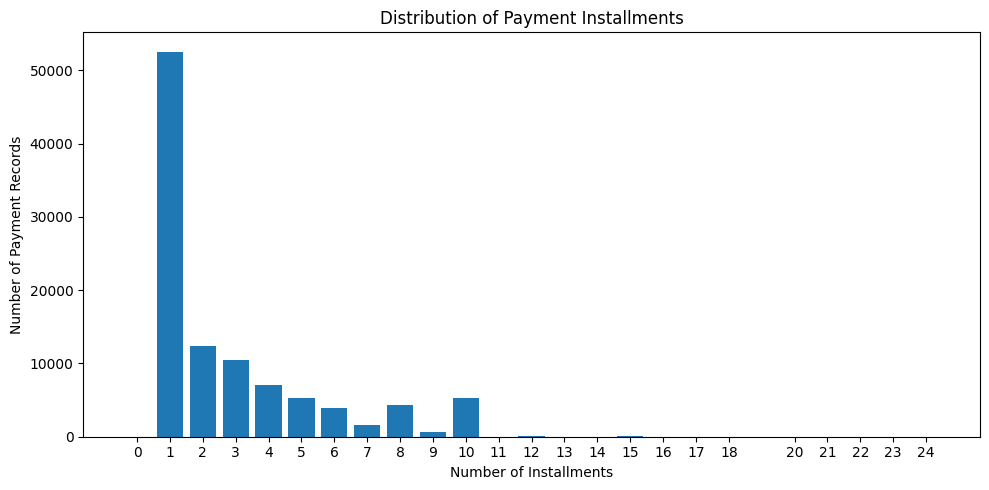

In [80]:
plt.figure(figsize=(10, 5))

plt.bar(
    installment_counts["installments"],
    installment_counts["payment_records"]
)

plt.title("Distribution of Payment Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Payment Records")
plt.xticks(installment_counts["installments"])
plt.tight_layout()
plt.show()

In [81]:
installment_analysis = (
    payments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "count"),
        average_payment_value=("payment_value", "mean"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
    .sort_values("payment_installments")
)

installment_analysis.head(20)

,payment_installments,payment_records,average_payment_value,total_payment_value
0,0,2,94.315000,188.63
1,1,52546,112.420229,5907233.36
2,2,12413,127.228150,1579283.03
3,3,10461,142.539317,1491103.80
4,4,7098,163.976840,1163907.61
5,5,5239,183.465222,961174.30
6,6,3920,209.849952,822611.81
7,7,1626,187.673672,305157.39
8,8,4268,307.737427,1313423.34
9,9,644,203.440870,131015.92


## Delivery Analysis

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

delivery_data = orders[
    [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Convert dates to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    delivery_data[col] = pd.to_datetime(
        delivery_data[col],
        errors="coerce"
    )

# Add customer state
delivery_data = delivery_data.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate actual delivery days
delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

delivery_data.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_state,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,SP,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,BA,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,GO,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,RN,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,SP,2.873877


## Delivery Days

In [83]:
delivered_orders = delivery_data[
    (delivery_data["order_status"] == "delivered")
    & (delivery_data["delivery_days"].notna())
    & (delivery_data["delivery_days"] >= 0)
].copy()

delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

In [84]:
print("Delivered Orders:", len(delivered_orders))

print(
    "Average Delivery Days:",
    round(delivered_orders["delivery_days"].mean(), 2)
)

print(
    "Median Delivery Days:",
    round(delivered_orders["delivery_days"].median(), 2)
)

print(
    "Fastest Delivery Days:",
    round(delivered_orders["delivery_days"].min(), 2)
)

print(
    "Slowest Delivery Days:",
    round(delivered_orders["delivery_days"].max(), 2)
)

Delivered Orders: 96470
Average Delivery Days: 12.56
Median Delivery Days: 10.22
Fastest Delivery Days: 0.53
Slowest Delivery Days: 209.63


## Delivery Distribution

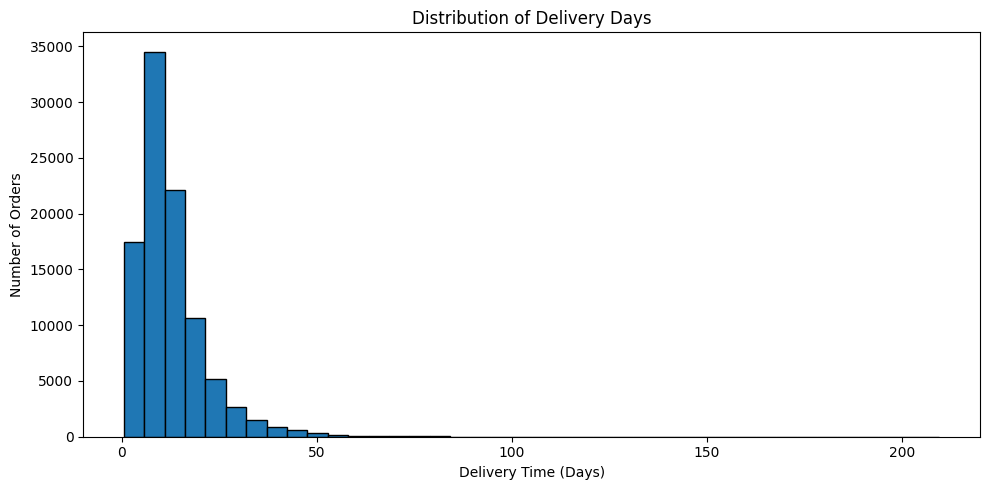

In [85]:
plt.figure(figsize=(10, 5))

plt.hist(
    delivered_orders["delivery_days"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

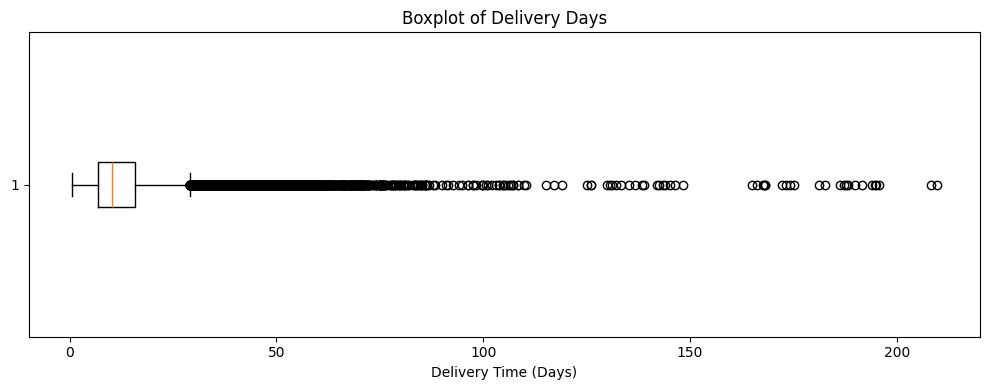

In [86]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    delivered_orders["delivery_days"],
    vert=False
)

plt.title("Boxplot of Delivery Days")
plt.xlabel("Delivery Time (Days)")
plt.tight_layout()
plt.show()

## Early, On-time, and Late Delivery

In [87]:
delivered_orders["delivery_difference_days"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    - delivered_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

conditions = [
    delivered_orders["delivery_difference_days"] < 0,
    delivered_orders["delivery_difference_days"] == 0,
    delivered_orders["delivery_difference_days"] > 0
]

labels = ["Early", "On-time", "Late"]

delivered_orders["delivery_status"] = pd.Series(
    pd.NA,
    index=delivered_orders.index,
    dtype="string"
)

import numpy as np

delivered_orders["delivery_status"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

delivered_orders["delivery_status"].value_counts()

delivery_status
Early      88644
Late        6534
On-time     1292
Name: count, dtype: int64

In [88]:
delivery_status_summary = (
    delivered_orders["delivery_status"]
    .value_counts()
    .rename_axis("delivery_status")
    .reset_index(name="total_orders")
)

delivery_status_summary["percentage"] = (
    delivery_status_summary["total_orders"]
    / delivery_status_summary["total_orders"].sum()
    * 100
)

delivery_status_summary

,delivery_status,total_orders,percentage
0,Early,88644,91.887633
1,Late,6534,6.773090
2,On-time,1292,1.339276


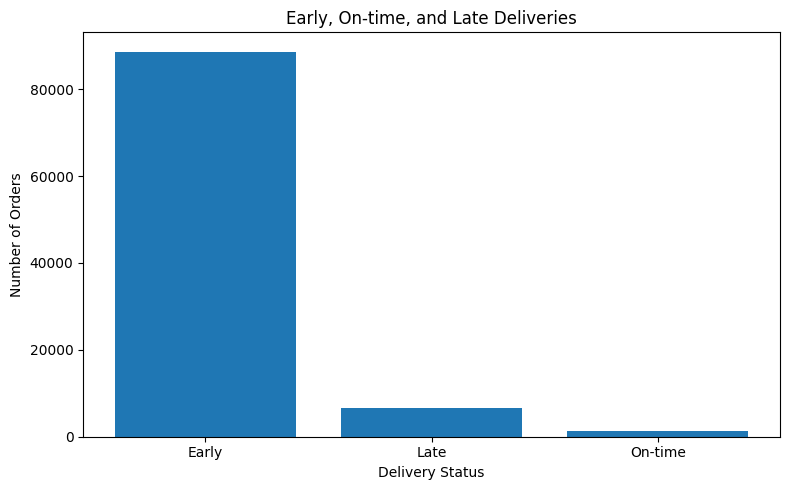

In [89]:
plt.figure(figsize=(8, 5))

plt.bar(
    delivery_status_summary["delivery_status"],
    delivery_status_summary["total_orders"]
)

plt.title("Early, On-time, and Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

## Delivery by State

In [90]:
delivery_by_state = (
    delivered_orders.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
    .reset_index()
    .sort_values("average_delivery_days", ascending=False)
)

delivery_by_state.head(10)

,customer_state,total_orders,average_delivery_days,median_delivery_days
21,RR,41,29.387546,25.007303
3,AP,67,27.185068,24.347025
2,AM,145,26.425991,25.875139
1,AL,397,24.543855,22.332917
13,PA,946,23.772917,21.078391
9,MA,717,21.572976,19.190602
24,SE,335,21.519788,18.014306
5,CE,1279,21.266579,18.209201
0,AC,80,21.035713,18.356528
14,PB,517,20.426768,18.152442


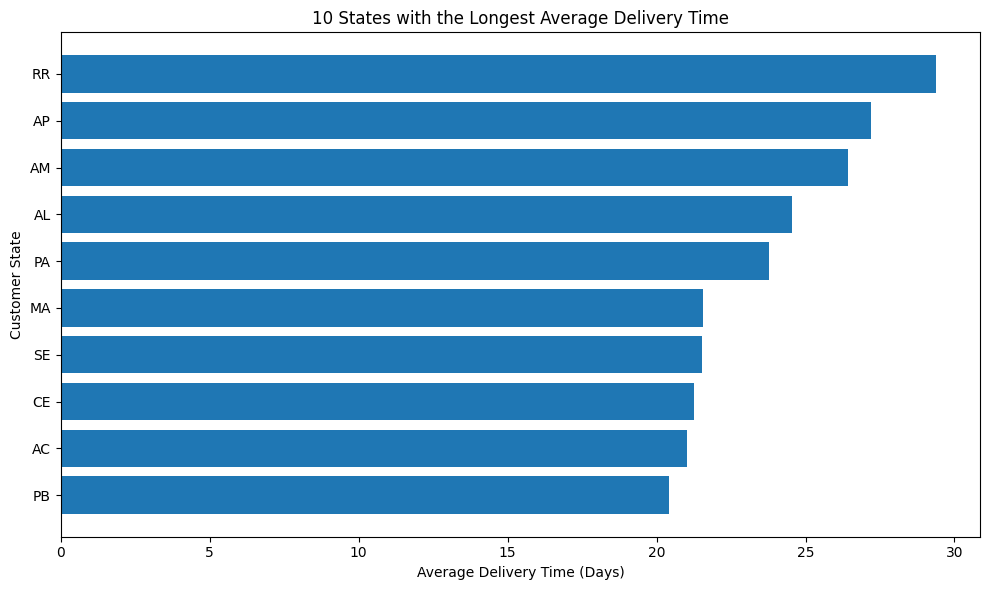

In [91]:
slowest_states = delivery_by_state.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    slowest_states["customer_state"],
    slowest_states["average_delivery_days"]
)

plt.title("10 States with the Longest Average Delivery Time")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Customer State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

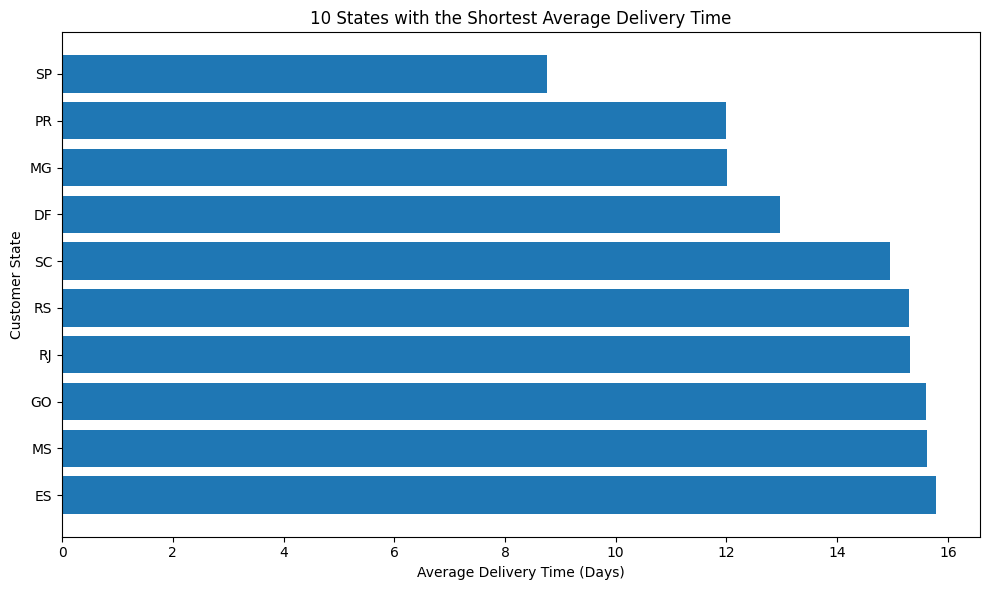

In [92]:
fastest_states = (
    delivery_by_state
    .sort_values("average_delivery_days")
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    fastest_states["customer_state"],
    fastest_states["average_delivery_days"]
)

plt.title("10 States with the Shortest Average Delivery Time")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Customer State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Review Analysis

In [93]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [94]:
review_data = reviews[
    ["review_id", "order_id", "review_score"]
].copy()

# Convert review scores to numeric
review_data["review_score"] = pd.to_numeric(
    review_data["review_score"],
    errors="coerce"
)

# Keep valid scores from 1 to 5
review_data = review_data[
    review_data["review_score"].between(1, 5)
].copy()

review_data.head()

,review_id,order_id,review_score
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5


## Review Distribution

In [95]:
review_distribution = (
    review_data["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = [
    "review_score",
    "total_reviews"
]

review_distribution["percentage"] = (
    review_distribution["total_reviews"]
    / review_distribution["total_reviews"].sum()
    * 100
)

review_distribution

,review_score,total_reviews,percentage
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


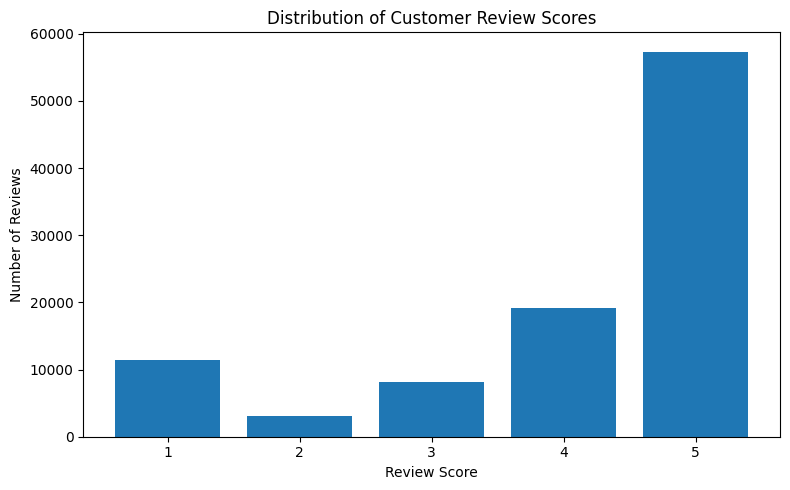

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    review_distribution["review_score"],
    review_distribution["total_reviews"]
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [97]:
print(
    "Average Review Score:",
    round(review_data["review_score"].mean(), 2)
)

print(
    "Total Reviews:",
    len(review_data)
)

print(
    "Percentage of 5-Star Reviews:",
    round(
        (review_data["review_score"] == 5).mean() * 100,
        2
    ),
    "%"
)

Average Review Score: 4.09
Total Reviews: 99224
Percentage of 5-Star Reviews: 57.78 %


### Review by Product Category

In [98]:
# Average review score for each order
order_reviews = (
    review_data.groupby("order_id")
    .agg(
        order_review_score=("review_score", "mean"),
        review_count=("review_id", "nunique")
    )
    .reset_index()
)

# Attach product information to order items
item_categories = order_items[
    ["order_id", "product_id"]
].merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Attach order-level review scores
category_reviews = item_categories.merge(
    order_reviews,
    on="order_id",
    how="inner",
    validate="many_to_one"
)

category_reviews.head()

,order_id,product_id,product_category_name,order_review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,4.0,1
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,perfumaria,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,5.0,1


In [99]:
category_review_summary = (
    category_reviews
    .groupby("product_category_name")
    .agg(
        average_review_score=("order_review_score", "mean"),
        total_items=("product_id", "count"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Focus on categories with at least 50 orders
category_review_summary = category_review_summary[
    category_review_summary["total_orders"] >= 50
].sort_values("average_review_score", ascending=False)

category_review_summary.head(10)

,product_category_name,average_review_score,total_items,total_orders
48,livros_interesse_geral,4.446266,549,508
22,construcao_ferramentas_ferramentas,4.444444,99,94
47,livros_importados,4.400000,60,53
49,livros_tecnicos,4.363636,264,257
50,malas_acessorios,4.315257,1088,1030
2,alimentos_bebidas,4.312274,277,226
64,portateis_casa_forno_e_cafe,4.302632,76,75
34,fashion_calcados,4.238372,258,236
1,alimentos,4.218182,495,445
59,papelaria,4.195478,2499,2295


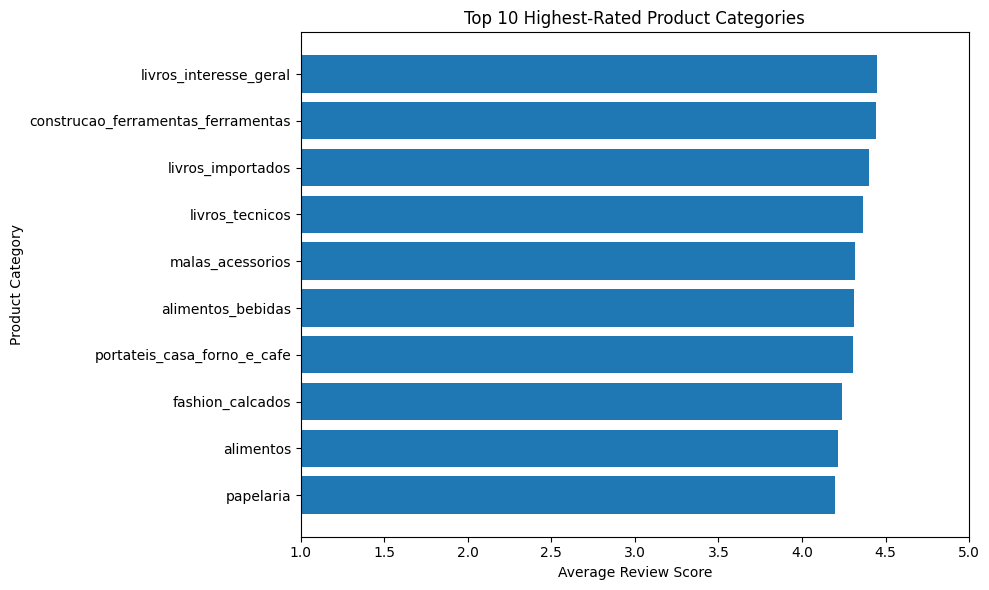

In [100]:
top_review_categories = category_review_summary.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_review_categories["product_category_name"],
    top_review_categories["average_review_score"]
)

plt.title("Top 10 Highest-Rated Product Categories")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(1, 5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

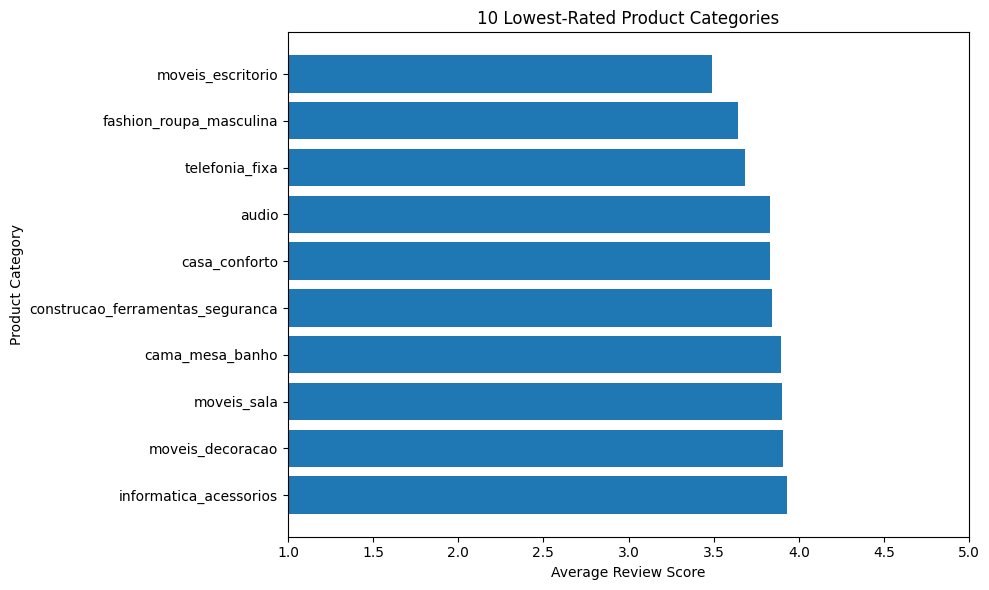

In [101]:
low_review_categories = (
    category_review_summary
    .sort_values("average_review_score")
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    low_review_categories["product_category_name"],
    low_review_categories["average_review_score"]
)

plt.title("10 Lowest-Rated Product Categories")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(1, 5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Delivery vs Review

In [102]:
delivery_review = delivery_data[
    [
        "order_id",
        "delivery_days",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "order_status"
    ]
].merge(
    order_reviews,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Keep valid delivered orders
delivery_review = delivery_review[
    (delivery_review["order_status"] == "delivered")
    & (delivery_review["delivery_days"].notna())
    & (delivery_review["delivery_days"] >= 0)
].copy()

# Calculate delivery difference in calendar days
delivery_review["delivery_difference_days"] = (
    delivery_review["order_delivered_customer_date"].dt.normalize()
    - delivery_review["order_estimated_delivery_date"].dt.normalize()
).dt.days

delivery_review.head()

,order_id,delivery_days,order_delivered_customer_date,order_estimated_delivery_date,order_status,order_review_score,review_count,delivery_difference_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,2017-10-10 21:25:13,2017-10-18,delivered,4.0,1,-8
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,2018-08-07 15:27:45,2018-08-13,delivered,4.0,1,-6
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,2018-08-17 18:06:29,2018-09-04,delivered,5.0,1,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,2017-12-02 00:28:42,2017-12-15,delivered,5.0,1,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,2018-02-16 18:17:02,2018-02-26,delivered,5.0,1,-10


In [103]:
import numpy as np

delivery_review["delivery_status"] = np.select(
    [
        delivery_review["delivery_difference_days"] < 0,
        delivery_review["delivery_difference_days"] == 0,
        delivery_review["delivery_difference_days"] > 0
    ],
    [
        "Early",
        "On-time",
        "Late"
    ],
    default="Unknown"
)

delivery_review_summary = (
    delivery_review
    .groupby("delivery_status")
    .agg(
        total_orders=("order_id", "nunique"),
        average_review_score=("order_review_score", "mean"),
        median_review_score=("order_review_score", "median")
    )
    .reset_index()
)

delivery_review_summary

,delivery_status,total_orders,average_review_score,median_review_score
0,Early,88163,4.294292,5.0
1,Late,6381,2.271823,1.0
2,On-time,1280,4.035547,5.0


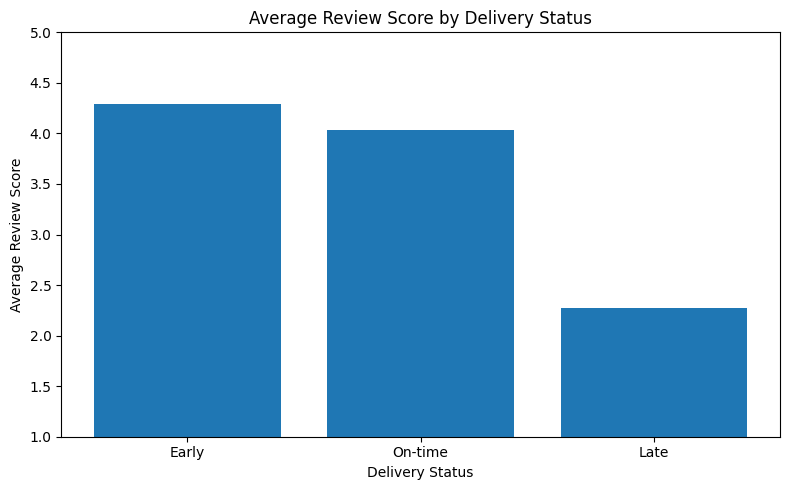

In [104]:
status_order = ["Early", "On-time", "Late"]

plot_data = (
    delivery_review_summary
    .set_index("delivery_status")
    .reindex(status_order)
    .dropna(subset=["average_review_score"])
    .reset_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["delivery_status"],
    plot_data["average_review_score"]
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()

In [105]:
correlation = delivery_review[
    ["delivery_days", "order_review_score"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))

Correlation: -0.334


## Geographic Analysis

In [106]:
import pandas as pd
import matplotlib.pyplot as plt

# One customer record per unique customer
customer_geo = customers.drop_duplicates(
    "customer_unique_id"
).copy()

# Aggregate product revenue by order
order_revenue = (
    order_items.groupby("order_id")
    .agg(total_revenue=("price", "sum"))
    .reset_index()
)

# Attach customer state to orders
geo_orders = orders[
    ["order_id", "customer_id", "order_status"]
].merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Attach product revenue
geo_orders = geo_orders.merge(
    order_revenue,
    on="order_id",
    how="left",
    validate="one_to_one"
)

geo_orders.head()

,order_id,customer_id,order_status,customer_state,total_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,SP,29.99
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,BA,118.70
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,GO,159.90
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,RN,45.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,SP,19.90


### Customer Distribution by State

In [107]:
customers_by_state = (
    customer_geo.groupby("customer_state")
    .agg(
        total_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("total_customers", ascending=False)
)

customers_by_state["customer_percentage"] = (
    customers_by_state["total_customers"]
    / customers_by_state["total_customers"].sum()
    * 100
)

customers_by_state.head(10)

,customer_state,total_customers,customer_percentage
25,SP,40295,41.932026
18,RJ,12377,12.879829
10,MG,11255,11.712246
22,RS,5277,5.491384
17,PR,4882,5.080336
23,SC,3529,3.672369
4,BA,3276,3.409091
6,DF,2073,2.157218
7,ES,1963,2.042749
8,GO,1951,2.030261


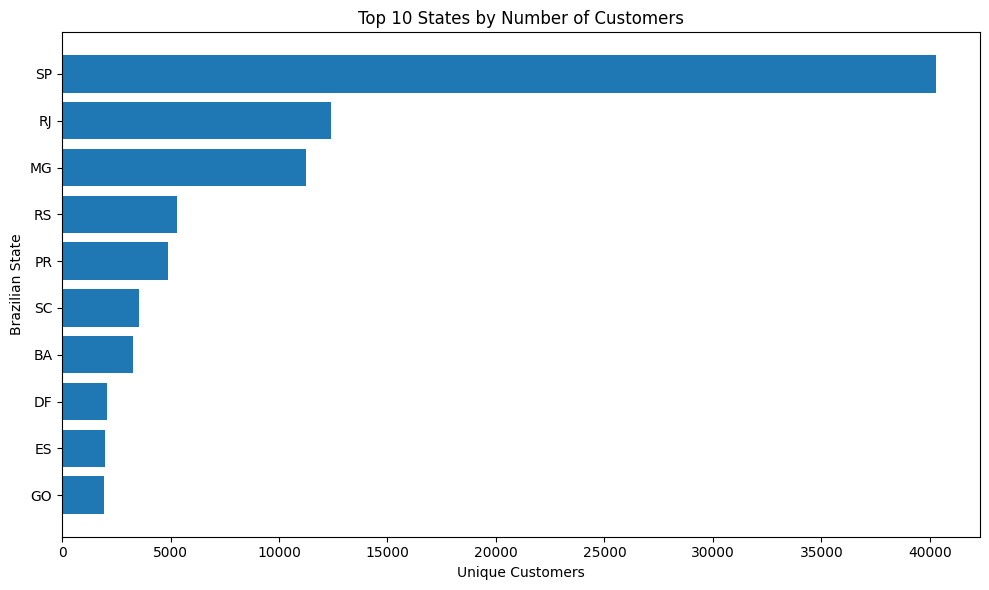

In [108]:
top_customer_states = customers_by_state.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_customer_states["customer_state"],
    top_customer_states["total_customers"]
)

plt.title("Top 10 States by Number of Customers")
plt.xlabel("Unique Customers")
plt.ylabel("Brazilian State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Seller Distribution by State

In [109]:
sellers_by_state = (
    sellers.groupby("seller_state")
    .agg(
        total_sellers=("seller_id", "nunique")
    )
    .reset_index()
    .sort_values("total_sellers", ascending=False)
)

sellers_by_state.head(10)

,seller_state,total_sellers
22,SP,1849
15,PR,349
8,MG,244
20,SC,190
16,RJ,171
19,RS,129
6,GO,40
4,DF,30
5,ES,23
2,BA,19


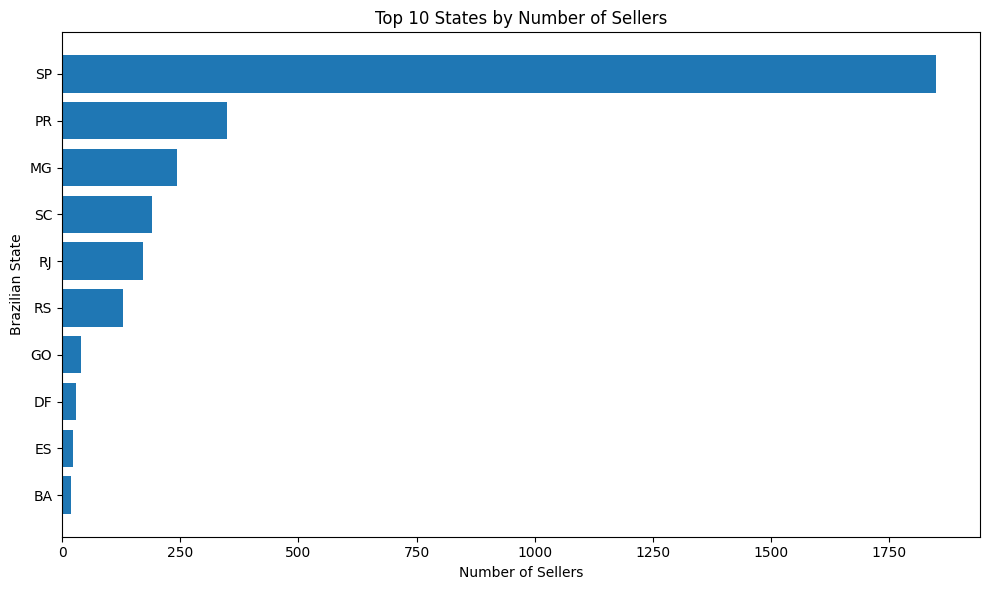

In [110]:
top_seller_states = sellers_by_state.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_seller_states["seller_state"],
    top_seller_states["total_sellers"]
)

plt.title("Top 10 States by Number of Sellers")
plt.xlabel("Number of Sellers")
plt.ylabel("Brazilian State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Revenue by State

In [111]:
revenue_by_state = (
    geo_orders.groupby("customer_state")
    .agg(
        total_revenue=("total_revenue", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

revenue_by_state["revenue_percentage"] = (
    revenue_by_state["total_revenue"]
    / revenue_by_state["total_revenue"].sum()
    * 100
)

revenue_by_state["revenue_per_order"] = (
    revenue_by_state["total_revenue"]
    / revenue_by_state["total_orders"]
)

revenue_by_state.head(10)

,customer_state,total_revenue,total_orders,revenue_percentage,revenue_per_order
25,SP,5202955.05,41746,38.280543,124.633619
18,RJ,1824092.67,12852,13.420692,141.930647
10,MG,1585308.03,11635,11.663843,136.253376
22,RS,750304.02,5466,5.520333,137.267475
17,PR,683083.76,5045,5.025763,135.398168
23,SC,520553.34,3637,3.829951,143.127121
4,BA,511349.99,3380,3.762238,151.286979
6,DF,302603.94,2140,2.226397,141.403710
8,GO,294591.95,2020,2.167449,145.837599
7,ES,275037.31,2033,2.023577,135.286429


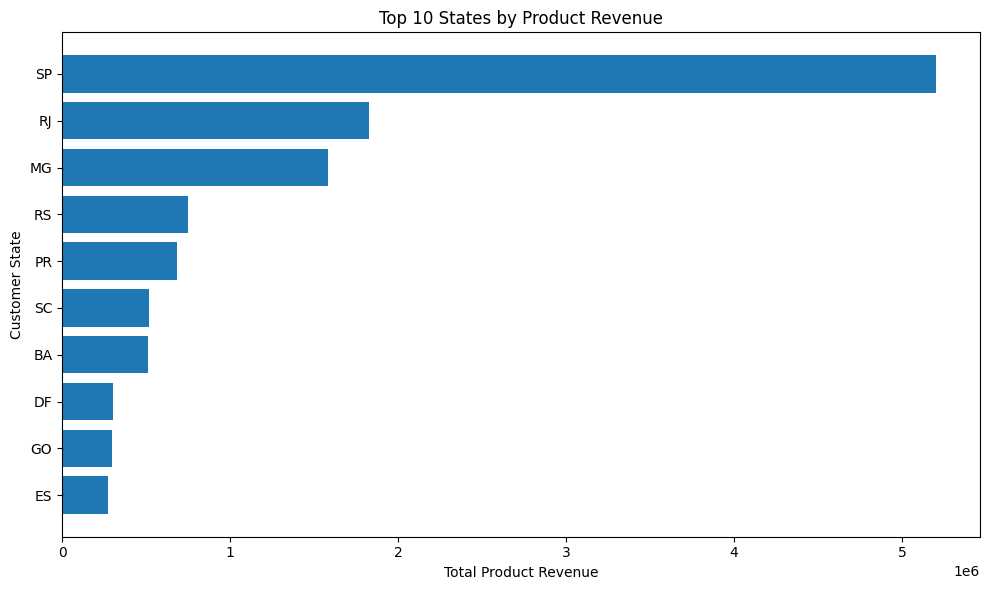

In [112]:
top_revenue_states = revenue_by_state.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_revenue_states["customer_state"],
    top_revenue_states["total_revenue"]
)

plt.title("Top 10 States by Product Revenue")
plt.xlabel("Total Product Revenue")
plt.ylabel("Customer State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Customer vs Seller Locations

In [113]:
customer_seller_comparison = customers_by_state[
    ["customer_state", "total_customers"]
].merge(
    sellers_by_state,
    left_on="customer_state",
    right_on="seller_state",
    how="outer"
)

customer_seller_comparison = customer_seller_comparison.drop(
    columns=["seller_state"]
)

customer_seller_comparison[
    ["total_customers", "total_sellers"]
] = customer_seller_comparison[
    ["total_customers", "total_sellers"]
].fillna(0)

customer_seller_comparison["customers_per_seller"] = (
    customer_seller_comparison["total_customers"]
    / customer_seller_comparison["total_sellers"].replace(0, pd.NA)
)

customer_seller_comparison = customer_seller_comparison.sort_values(
    "total_customers",
    ascending=False
)

customer_seller_comparison.head(10)

,customer_state,total_customers,total_sellers,customers_per_seller
25,SP,40295,1849.0,21.792861
18,RJ,12377,171.0,72.380117
10,MG,11255,244.0,46.127049
22,RS,5277,129.0,40.906977
17,PR,4882,349.0,13.988539
23,SC,3529,190.0,18.573684
4,BA,3276,19.0,172.421053
6,DF,2073,30.0,69.1
7,ES,1963,23.0,85.347826
8,GO,1951,40.0,48.775


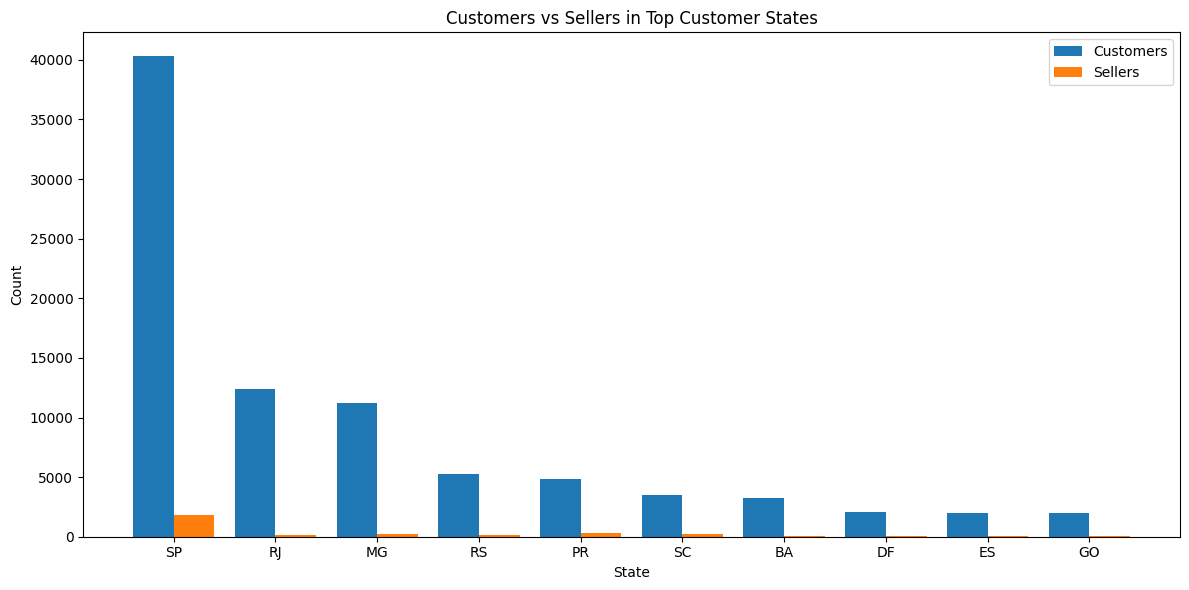

In [114]:
comparison_data = customer_seller_comparison.head(10)

x = range(len(comparison_data))
width = 0.4

plt.figure(figsize=(12, 6))

plt.bar(
    [i - width / 2 for i in x],
    comparison_data["total_customers"],
    width=width,
    label="Customers"
)

plt.bar(
    [i + width / 2 for i in x],
    comparison_data["total_sellers"],
    width=width,
    label="Sellers"
)

plt.title("Customers vs Sellers in Top Customer States")
plt.xlabel("State")
plt.ylabel("Count")
plt.xticks(list(x), comparison_data["customer_state"])
plt.legend()
plt.tight_layout()
plt.show()

In [115]:
from pathlib import Path
import pandas as pd

# Folder for all exported analysis tables
output_dir = Path(
    r"C:\Users\LATO\Documents\Sales Analysis\Analysis Tables"
)
output_dir.mkdir(parents=True, exist_ok=True)

# All analysis tables created during EDA
analysis_tables = {
    # Business overview and sales
    "order_analysis": "order_analysis",
    "order_revenue": "order_revenue",
    "sales_data": "sales_data",
    "monthly_aov": "monthly_aov",
    "status_analysis": "status_analysis",

    # Product analysis
    "product_analysis": "product_analysis",
    "product_sales": "product_sales",
    "category_sales": "category_sales",

    # Customer analysis
    "customer_analysis": "customer_analysis",
    "customer_orders": "customer_orders",
    "customer_order_counts": "customer_order_counts",
    "customer_spending": "customer_spending",
    "customer_geography": "customer_geography",

    # Seller analysis
    "seller_analysis": "seller_analysis",
    "seller_performance": "seller_performance",
    "top_sellers": "top_sellers",
    "top_revenue_sellers": "top_revenue_sellers",

    # Payment analysis
    "payment_methods": "payment_methods",
    "payment_value_analysis": "payment_value_analysis",
    "installment_analysis": "installment_analysis",

    # Delivery analysis
    "delivery_data": "delivery_data",
    "delivered_orders": "delivered_orders",
    "delivery_status_summary": "delivery_status_summary",
    "delivery_by_state": "delivery_by_state",

    # Review analysis
    "review_data": "review_data",
    "review_distribution": "review_distribution",
    "order_reviews": "order_reviews",
    "category_review_summary": "category_review_summary",
    "delivery_review_summary": "delivery_review_summary",

    # Geographic analysis
    "customers_by_state": "customers_by_state",
    "sellers_by_state": "sellers_by_state",
    "revenue_by_state": "revenue_by_state",
    "customer_seller_comparison": "customer_seller_comparison",
}

# Export only tables that currently exist in notebook memory
exported = []
missing = []

for variable_name, file_name in analysis_tables.items():
    if variable_name in globals():
        obj = globals()[variable_name]

        if isinstance(obj, pd.DataFrame):
            obj.to_csv(
                output_dir / f"{file_name}.csv",
                index=False
            )
            exported.append(file_name)
        else:
            missing.append(variable_name + " (not a DataFrame)")
    else:
        missing.append(variable_name)

print(f"Exported {len(exported)} tables to:")
print(output_dir)

print("\nExported tables:")
for name in exported:
    print(f"  - {name}.csv")

print("\nTables not exported because they were missing or unavailable:")
for name in missing:
    print(f"  - {name}")


Exported 32 tables to:
C:\Users\LATO\Documents\Sales Analysis\Analysis Tables

Exported tables:
  - order_analysis.csv
  - order_revenue.csv
  - sales_data.csv
  - monthly_aov.csv
  - status_analysis.csv
  - product_analysis.csv
  - product_sales.csv
  - customer_analysis.csv
  - customer_orders.csv
  - customer_order_counts.csv
  - customer_spending.csv
  - customer_geography.csv
  - seller_analysis.csv
  - seller_performance.csv
  - top_sellers.csv
  - top_revenue_sellers.csv
  - payment_methods.csv
  - payment_value_analysis.csv
  - installment_analysis.csv
  - delivery_data.csv
  - delivered_orders.csv
  - delivery_status_summary.csv
  - delivery_by_state.csv
  - review_data.csv
  - review_distribution.csv
  - order_reviews.csv
  - category_review_summary.csv
  - delivery_review_summary.csv
  - customers_by_state.csv
  - sellers_by_state.csv
  - revenue_by_state.csv
  - customer_seller_comparison.csv

Tables not exported because they were missing or unavailable:
  - category_sales
